# Mô hình 2: Random Forest Regressor - dự đoán điểm đánh giá trung bình (học giám sát)
**Biến mục tiêu:** diem_danh_gia_trung_binh. Chỉ huấn luyện trên sản phẩm có đánh giá hợp lệ
(so_luot_danh_gia > 0 và điểm từ 1 đến 5). Sản phẩm chưa có đánh giá KHÔNG được dùng điểm 0 làm nhãn.

**Đầu vào:** gia_ban, gia_goc, ty_le_giam_gia, so_luot_danh_gia, so_luong_da_ban, nguon, ten_danh_muc (one-hot).
**Đánh giá:** MAE, RMSE, R² trên tập test (20%), so với mô hình cơ sở luôn dự đoán điểm trung bình.

In [1]:
# 1. Thư viện và đọc dữ liệu
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from common import (MODELS_DIR, load_products, prepare_ml_data, save_metrics, save_results, savefig,
                    them_cot_co_dau)

TARGET = "Điểm đánh giá trung bình"
NUM = ["Giá bán", "Giá gốc", "Tỷ lệ giảm giá", "Số lượt đánh giá", "Số lượng đã bán"]
CAT = ["Nguồn dữ liệu", "Tên danh mục"]

raw = load_products()
df = them_cot_co_dau(prepare_ml_data(raw))          # rating 0 -> NaN nên sẽ bị loại ở bước lọc bên dưới

[Mongo] Kết nối thành công, database = ecommerce_db
[Dữ liệu] Đọc từ MongoDB ecommerce_db.products_cleaned: 6945 dòng


In [2]:
# 2. Lọc dữ liệu hợp lệ
d = df[(df["Số lượt đánh giá"] > 0) & df[TARGET].between(1, 5)].copy()
print(f"Tổng sản phẩm: {len(df)} | dùng để huấn luyện/kiểm tra: {len(d)} | loại: {len(df) - len(d)}")
print(d["nguon"].value_counts().to_string())
print("Thiếu so_luong_da_ban trong tập dùng:", int(d["Số lượng đã bán"].isna().sum()), "(sẽ điền trung vị)")
print("\nPhân bố điểm đánh giá:\n", d[TARGET].describe().round(3))

Tổng sản phẩm: 6945 | dùng để huấn luyện/kiểm tra: 3929 | loại: 3016
nguon
hasaki    1986
tiki      1943
Thiếu so_luong_da_ban trong tập dùng: 13 (sẽ điền trung vị)

Phân bố điểm đánh giá:
 count    3929.000
mean        4.838
std         0.318
min         1.000
25%         4.800
50%         5.000
75%         5.000
max         5.000
Name: Điểm đánh giá trung bình, dtype: float64


In [3]:
# 3. Chia train/test 80/20
X_tr, X_te, y_tr, y_te = train_test_split(d[NUM + CAT], d[TARGET], test_size=0.2, random_state=42)
print("Train:", len(X_tr), "| Test:", len(X_te))

Train: 3143 | Test: 786


In [4]:
# 4. Huấn luyện Random Forest và mô hình cơ sở
pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), NUM),
                         ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10), CAT)])
rf = Pipeline([("pre", pre),
               ("rf", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42))])
rf.fit(X_tr, y_tr)
base = DummyRegressor(strategy="mean").fit(X_tr, y_tr)      # luôn dự đoán điểm trung bình của tập train


def score(m):
    p = m.predict(X_te)
    return {"MAE": float(mean_absolute_error(y_te, p)),
            "RMSE": float(mean_squared_error(y_te, p) ** 0.5),
            "R2": float(r2_score(y_te, p))}


res = {"random_forest": score(rf), "baseline": score(base)}
print(pd.DataFrame(res).T.round(4))
cai_thien = (res["baseline"]["MAE"] - res["random_forest"]["MAE"]) / res["baseline"]["MAE"] * 100
print(f"MAE của Random Forest {'thấp' if cai_thien > 0 else 'CAO'} hơn mô hình cơ sở {abs(cai_thien):.1f}%")

# Kiểm tra lại bằng cross-validation 5 fold trên tập train (để chắc kết quả không do chia ngẫu nhiên)
cv_rf = -cross_val_score(rf, X_tr, y_tr, cv=5, scoring="neg_mean_absolute_error")
cv_base = -cross_val_score(DummyRegressor(strategy="mean"), X_tr, y_tr, cv=5, scoring="neg_mean_absolute_error")
print(f"CV 5-fold MAE: Random Forest {cv_rf.mean():.4f} (+/-{cv_rf.std():.4f}) | cơ sở {cv_base.mean():.4f}")

                  MAE    RMSE      R2
random_forest  0.1683  0.3125  0.0864
baseline       0.1903  0.3269 -0.0000
MAE của Random Forest thấp hơn mô hình cơ sở 11.6%
CV 5-fold MAE: Random Forest 0.1661 (+/-0.0087) | cơ sở 0.1840


[Biểu đồ] output\figures\rf_do_quan_trong.png


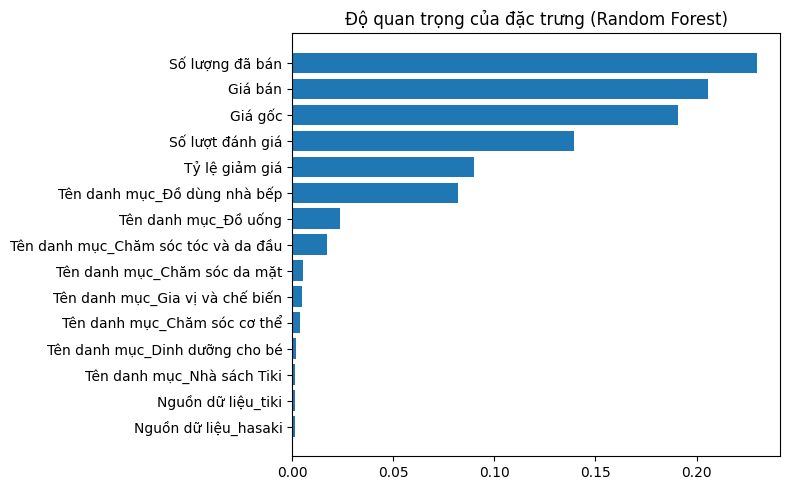

num__Số lượng đã bán                        0.2298
num__Giá bán                                0.2059
num__Giá gốc                                0.1909
num__Số lượt đánh giá                       0.1396
num__Tỷ lệ giảm giá                         0.0902
cat__Tên danh mục_Đồ dùng nhà bếp           0.0820
cat__Tên danh mục_Đồ uống                   0.0236
cat__Tên danh mục_Chăm sóc tóc và da đầu    0.0173
cat__Tên danh mục_Chăm sóc da mặt           0.0053
cat__Tên danh mục_Gia vị và chế biến        0.0049
dtype: float64


In [5]:
# 5. Biểu đồ độ quan trọng của đặc trưng
names = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["rf"].feature_importances_, index=names).sort_values(ascending=False)
top = imp.head(15)[::-1]
plt.figure(figsize=(8, 5))
plt.barh([n.split("__", 1)[-1] for n in top.index], top.values)
plt.title("Độ quan trọng của đặc trưng (Random Forest)")
savefig(plt, "rf_do_quan_trong")
plt.show()
print(imp.head(10).round(4))

[Biểu đồ] output\figures\rf_du_doan_vs_thuc_te.png


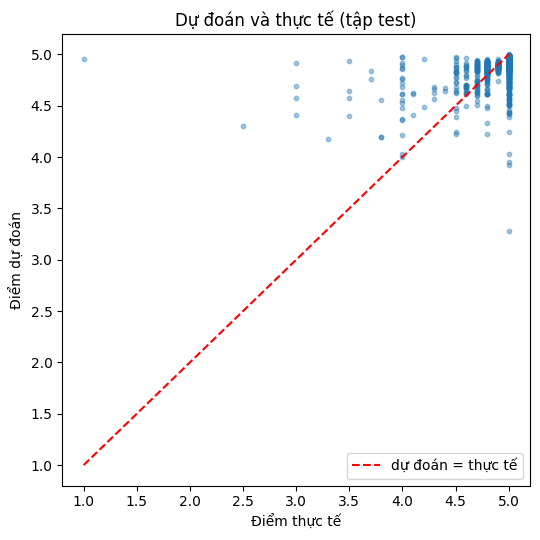

In [6]:
# 6. Biểu đồ dự đoán so với thực tế (tập test)
pred_te = rf.predict(X_te)
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_te, pred_te, s=10, alpha=0.4)
plt.plot([1, 5], [1, 5], "r--", label="dự đoán = thực tế")
plt.xlabel("Điểm thực tế"); plt.ylabel("Điểm dự đoán"); plt.title("Dự đoán và thực tế (tập test)")
plt.legend()
savefig(plt, "rf_du_doan_vs_thuc_te")
plt.show()

In [7]:
# 7. Lưu mô hình, kết quả và chỉ số
d["rating_du_doan"] = np.clip(rf.predict(d[NUM + CAT]), 1, 5).round(2)
d["rating_thuc"] = d[TARGET]
d["sai_so"] = (d["rating_du_doan"] - d["rating_thuc"]).round(2)
d["tap_du_lieu"] = np.where(d.index.isin(X_te.index), "test", "train")   # cột thêm: để biết dòng nào là test

joblib.dump({"model": rf, "features": NUM + CAT, "version": "v1"}, MODELS_DIR / "rf_rating.pkl")
save_results("ml_rating_predictions",
             d[["nguon", "ma_san_pham", "rating_thuc", "rating_du_doan", "sai_so", "tap_du_lieu"]])
save_metrics("random_forest_rating",
             metrics={**res, "mae_cai_thien_so_voi_co_so_pct": float(cai_thien),
                      "cv5_mae_rf": float(cv_rf.mean()), "cv5_mae_baseline": float(cv_base.mean()),
                      "n_test": int(len(X_te)),
                      "top_dac_trung": {k: float(v) for k, v in imp.head(5).items()}},
             params={"n_estimators": 300, "min_samples_leaf": 3, "test_size": 0.2, "random_state": 42,
                     "features": NUM + CAT, "loc": "so_luot_danh_gia>0 va diem trong [1,5]"},
             n_train=len(X_tr))

[Lưu] ml_rating_predictions: DataFrame 3929 dòng, MongoDB 3929 document, KHỚP
[Lưu] ml_model_metrics: đã ghi random_forest_rating
